In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
Customer = pd.read_excel('Customers_dataset.xlsx')
Customer.head()

,customer_id,customer_zip_code,gender,age_group,customer_segment
0,C00001,690511,Female,36-45,Loyal
1,C00002,509152,Male,26-35,New
2,C00003,477335,Male,26-35,Loyal
3,C00004,140413,Female,65+,Loyal
4,C00005,700009,Male,26-35,Loyal


In [3]:
Product = pd.read_excel('Products_dataset.xlsx')
Product.head()

,product_id,Category_name,sub_category_name,product_weight_g,brand,cost_price,selling_price,stock_availability
0,P00001,perfumery,Fragrances,225,Nivea,2200,2860,In Stock
1,P00002,art,General Merchandise,1000,Generic Global,110,140,In Stock
2,P00003,sports_leisure,General Merchandise,154,Generic Indian,14680,17170,In Stock
3,P00004,baby,Collectibles,371,Generic Indian,3890,4920,In Stock
4,P00005,housewares,Novelty Items,625,Generic Indian,12590,16220,In Stock


In [4]:
Orders = pd.read_excel("Orders_Dataset_Cleaned.xlsx")
Orders.head()

,order_id,customer_id,order_status,payment_type,order_purchase_timestamp,order_approved_at,order_delivered_shipping_date,order_delivered_customer_date,order_estimated_delivery_date
0,O00001,C60210,delivered,Net Banking,2024-11-04,2024-11-04,2024-12-01,2025-03-04,2025-01-03
1,O00002,C01893,delivered,Net Banking,2023-09-01,2023-09-01,2023-10-01,2023-10-05,2023-10-31
2,O00003,C19454,cancelled,UPI,2021-08-06,2021-08-06,2021-08-16,2021-08-19,2021-08-17
3,O00004,C67148,delivered,UPI,2025-07-07,2025-07-07,2025-10-06,2025-10-12,2025-07-12
4,O00005,C56280,delivered,Net Banking,2024-03-30,2024-03-30,2024-03-31,2024-04-04,2024-04-07


In [5]:
Order_item = pd.read_excel('Order_items_dataset.xlsx')
Order_item.head()

,order_item_id,order_id,quantity,product_id,unit_price,discount(%),shipping_cost
0,OI000001,O00001,1,P28355,7020,6.54,713.72
1,OI000002,O00002,1,P04408,7590,20.56,1212.02
2,OI000003,O00002,2,P14887,14360,24.67,1478.39
3,OI000004,O00003,2,P02014,1530,12.06,155.12
4,OI000005,O00003,1,P27255,1560,10.51,188.03


In [6]:
Review = pd.read_excel('Review_Dataset_Cleaned.xlsx')
Review.head()

,review_id,order_id,review_score,review_comment_message,Delivered Date,review_date,order_delivered_customer_date
0,R89199,O00001,1,Item arrived damaged.,2025-03-04,2025-04-05,2025-03-04
1,R37310,O00002,5,Great product and quick delivery.,2023-10-05,2023-05-13,2023-10-05
2,R03279,O00003,4,Great product and quick delivery.,2021-08-19,2021-06-11,2021-08-19
3,R75596,O00004,5,Product as described. Good value.,2025-10-12,2025-12-19,2025-10-12
4,R88660,O00005,5,Very satisfied with the purchase.,2024-04-04,2024-04-17,2024-04-04


In [7]:
Location = pd.read_excel('Location_Dataset_Cleaned.xlsx')
Location.head()

,geolocation_zip_code,geolocation_city,geolocation_state,geolocation_lat,geolocation_lng,region
0,744301,Sawai,Andaman & Nicobar Islands,7.5166,93.6031,East
1,744301,Mus,Andaman & Nicobar Islands,9.2333,92.7833,East
2,744301,Kakana,Andaman & Nicobar Islands,9.1167,92.8000,East
3,744301,Carnicobar,Andaman & Nicobar Islands,9.1833,92.7667,East
4,744301,Lapathy,Andaman & Nicobar Islands,9.1833,92.7667,East


## Objective - 6

### Task 1 :- Identify the key factors influencing customer purchase conversion and repeat purchases using statistical analysis. 

In [41]:
sales = (
    Orders
    .merge(Customer, on='customer_id')
    .merge(Order_item, on='order_id')
    .merge(Product, on='product_id')
    .merge(Review[['order_id','review_score']], on='order_id', how='left')
)

sales.head()

,order_id,customer_id,order_status,payment_type,order_purchase_timestamp,order_approved_at,order_delivered_shipping_date,order_delivered_customer_date,order_estimated_delivery_date,customer_zip_code,...,discount(%),shipping_cost,Category_name,sub_category_name,product_weight_g,brand,cost_price,selling_price,stock_availability,review_score
0,O00001,C60210,delivered,Net Banking,2024-11-04,2024-11-04,2024-12-01,2025-03-04,2025-01-03,413514,...,6.54,713.72,sports_leisure,Novelty Items,1325,Generic Indian,5330,7020,In Stock,1.0
1,O00002,C01893,delivered,Net Banking,2023-09-01,2023-09-01,2023-10-01,2023-10-05,2023-10-31,523230,...,20.56,1212.02,sports_leisure,Novelty Items,24700,Generic Indian,6190,7590,In Stock,5.0
2,O00002,C01893,delivered,Net Banking,2023-09-01,2023-09-01,2023-10-01,2023-10-05,2023-10-31,523230,...,24.67,1478.39,health_beauty,Gifts,400,Generic Indian,11720,14360,In Stock,5.0
3,O00003,C19454,cancelled,UPI,2021-08-06,2021-08-06,2021-08-16,2021-08-19,2021-08-17,532186,...,12.06,155.12,garden_tools,General Merchandise,5400,Generic Indian,1300,1530,In Stock,4.0
4,O00003,C19454,cancelled,UPI,2021-08-06,2021-08-06,2021-08-16,2021-08-19,2021-08-17,532186,...,10.51,188.03,toys,Collectibles,650,Generic Indian,1300,1560,In Stock,4.0


In [42]:
sales['purchase_conversion'] = sales['order_status'].apply(
    lambda x: 1 if x == 'delivered' else 0
)

sales.sample(2)

,order_id,customer_id,order_status,payment_type,order_purchase_timestamp,order_approved_at,order_delivered_shipping_date,order_delivered_customer_date,order_estimated_delivery_date,customer_zip_code,...,shipping_cost,Category_name,sub_category_name,product_weight_g,brand,cost_price,selling_price,stock_availability,review_score,purchase_conversion
74697,O33109,C12127,delivered,Net Banking,2024-02-06,2024-02-06,2024-03-06,2024-03-10,2024-04-06,638051,...,777.52,bed_bath_table,Collectibles,9450,Generic Indian,6110,7520,In Stock,1.0,1
120016,O53275,C84495,returned,UPI,2024-03-19,2024-03-19,2024-07-17,2024-09-16,2024-05-04,174303,...,1014.92,bed_bath_table,Novelty Items,1700,Generic Indian,9850,12340,In Stock,5.0,0


In [43]:
sales['repeat_purchase'] = (sales.groupby('customer_id')['order_id'].transform('count').gt(1).astype(int))

sales.sample(2)

,order_id,customer_id,order_status,payment_type,order_purchase_timestamp,order_approved_at,order_delivered_shipping_date,order_delivered_customer_date,order_estimated_delivery_date,customer_zip_code,...,Category_name,sub_category_name,product_weight_g,brand,cost_price,selling_price,stock_availability,review_score,purchase_conversion,repeat_purchase
4553,O02020,C23444,shipped,UPI,2023-06-26,2023-06-26,2023-08-25,2023-08-28,2023-08-25,508258,...,stationery,Pens,2900,Faber-Castell,2000,2420,In Stock,NaN,0,1
110904,O49230,C67122,returned,UPI,2023-10-22,2023-10-22,2023-12-21,2023-12-27,2023-12-09,756045,...,stationery,Novels,400,Camel,1630,2300,In Stock,5.0,0,1


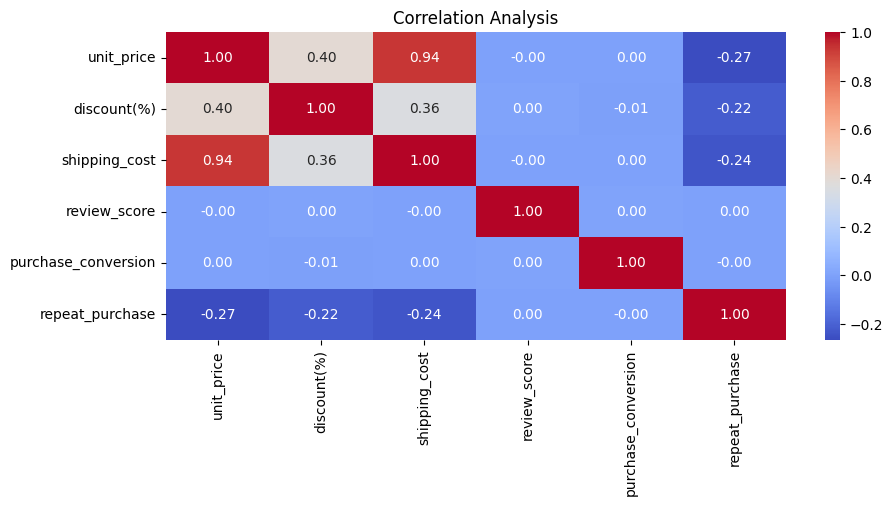

In [46]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = sales[['unit_price','discount(%)',
              'shipping_cost','review_score',
              'purchase_conversion','repeat_purchase']].corr()

plt.figure(figsize=(10,4))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Analysis")
plt.show()

In [13]:
X = sales[['unit_price','discount(%)',
           'shipping_cost','review_score']].fillna(0)

In [14]:
y = sales['purchase_conversion']

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [16]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

print("Model Accuracy:", model.score(X_test, y_test))

Model Accuracy: 0.8465666666666667


### Task 2 :- Build a machine learning model to predict whether a customer is likely to make a repeat purchase. 

In [17]:
import pandas as pd

sales = (
    Orders
    .merge(Customer, on='customer_id')
    .merge(Order_item, on='order_id')
    .merge(Product, on='product_id')
    .merge(Review[['order_id','review_score']], on='order_id', how='left')
)

In [18]:
sales['repeat_purchase'] = (
    sales.groupby('customer_id')['order_id']
    .transform('count')
    .gt(1)
    .astype(int)
)

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Features
X = sales[['unit_price',
           'discount(%)',
           'shipping_cost',
           'review_score']]

In [20]:
X = X.fillna(0)

In [21]:
y = sales['repeat_purchase']

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [23]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [24]:
accuracy = model.score(X_test, y_test)

print("Model Accuracy:", accuracy)

Model Accuracy: 0.9416333333333333


### Task 3 :- Compare multiple classification models to determine the best-performing customer retention prediction model. 

In [26]:
sales = (
    Orders
    .merge(Customer, on='customer_id')
    .merge(Order_item, on='order_id')
    .merge(Product, on='product_id')
    .merge(Review[['order_id', 'review_score']], on='order_id', how='left')
)

In [27]:
sales['customer_retention'] = (
    sales.groupby('customer_id')['order_id']
    .transform('count')
    .gt(1)
    .astype(int)
)

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [29]:
X = sales[['unit_price',
           'discount(%)',
           'shipping_cost',
           'review_score']].fillna(0)

In [30]:
y = sales['customer_retention']

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [32]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

In [33]:
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)
    print(f"{name}: {accuracy:.2f}")

Logistic Regression: 0.94
Decision Tree: 0.90
Random Forest: 0.94


### Task 4 :- Evaluate model performance using classification metrics and recommend the most effective model for business decisions.

In [34]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [35]:
X = sales[['unit_price',
           'discount(%)',
           'shipping_cost',
           'review_score']].fillna(0)

y = sales['customer_retention']

In [36]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [37]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

In [38]:
for name, model in models.items():

    model.fit(X_train, y_train)

    prediction = model.predict(X_test)

    print("="*50)
    print(name)
    print("Accuracy :", accuracy_score(y_test, prediction))
    print(classification_report(y_test, prediction))

Logistic Regression
Accuracy : 0.9416333333333333
              precision    recall  f1-score   support

           0       0.39      0.05      0.09      1700
           1       0.95      0.99      0.97     28300

    accuracy                           0.94     30000
   macro avg       0.67      0.52      0.53     30000
weighted avg       0.91      0.94      0.92     30000

Decision Tree
Accuracy : 0.9026333333333333
              precision    recall  f1-score   support

           0       0.18      0.21      0.19      1700
           1       0.95      0.94      0.95     28300

    accuracy                           0.90     30000
   macro avg       0.57      0.57      0.57     30000
weighted avg       0.91      0.90      0.91     30000

Random Forest
Accuracy : 0.9390666666666667
              precision    recall  f1-score   support

           0       0.35      0.09      0.14      1700
           1       0.95      0.99      0.97     28300

    accuracy                           0.94 